# Experiment No. 3
# Aim: Classification Analysis using Support Vector Machine (SVM)

Step 1: Import required libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

Step 2: Load the handwritten digits dataset

In [2]:
digits = load_digits()

# Store image data and target labels
X = digits.data
y = digits.target

print("Dataset loaded successfully")

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

print("\nFirst 5 target values:")
print(y[:5])


Dataset loaded successfully

Shape of X: (1797, 64)
Shape of y: (1797,)

First 5 target values:
[0 1 2 3 4]


 Step 3: Display handwritten digit images

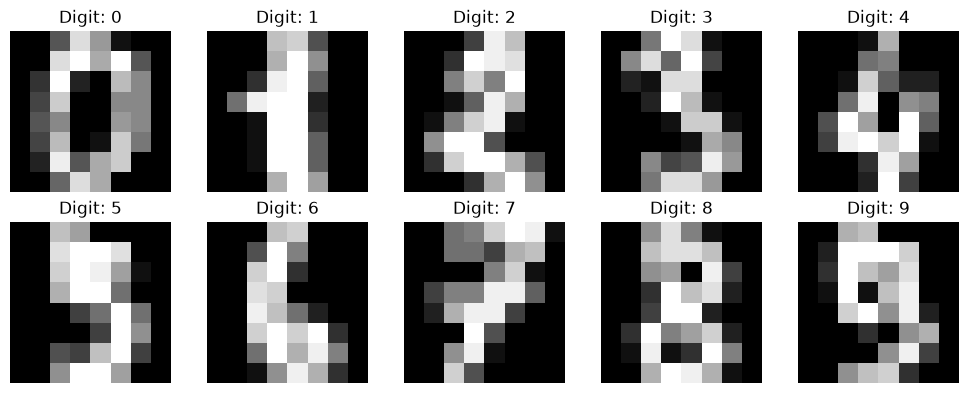

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(digits.images[i], cmap="gray")

    plt.title("Digit: " + str(y[i]))

    plt.axis("off")

plt.tight_layout()
plt.show()

 Step 4: Split the dataset into training and testing data

In [20]:
X_train, X_test, y_train, y_test, train_idx, test_idx = train_test_split(
    X, y, np.arange(len(y)),
    test_size=0.2,
    random_state=42,
    stratify=y
)

 Step 5: Standardize the data

In [21]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Step 6: Create SVM classifier

In [22]:
svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

 Step 7: Train the SVM model

In [23]:
svm_model.fit(X_train, y_train)

print("\nSVM model trained successfully")


SVM model trained successfully


Step 8: Predict the test data

In [24]:
y_pred = svm_model.predict(X_test)

print("\nPredicted values:")
print(y_pred[:20])

print("\nActual values:")
print(y_test[:20])


Predicted values:
[5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]

Actual values:
[5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]


Step 9: Calculate classification accuracy

In [25]:
accuracy = accuracy_score(y_test, y_pred)

print("\nClassification Accuracy:")
print(accuracy * 100, "%")


Classification Accuracy:
98.05555555555556 %


 Step 10: Display classification report

In [26]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.95      0.97      0.96        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



Step 11: Generate confusion matrix

In [27]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)



Confusion Matrix:
[[36  0  0  0  0  0  0  0  0  0]
 [ 0 35  0  0  1  0  0  0  0  0]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 35  0  0  1  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 36  0  0  0]
 [ 0  0  0  0  0  1  0 35  0  0]
 [ 0  1  0  0  1  0  0  0 33  0]
 [ 0  0  0  0  0  0  1  1  0 34]]


Step 12: Visualize confusion matrix

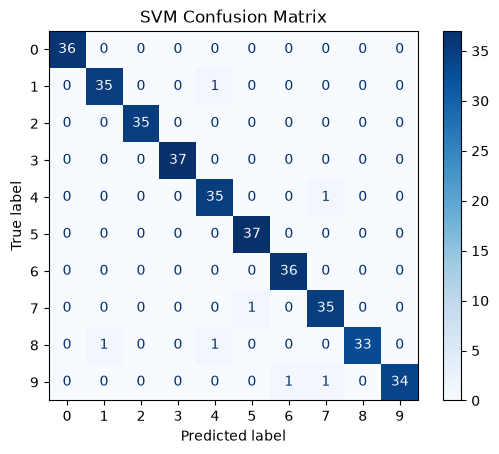

In [28]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=digits.target_names
)

disp.plot(cmap="Blues")

plt.title("SVM Confusion Matrix")

plt.show()

 Step 13: Display actual and predicted digits

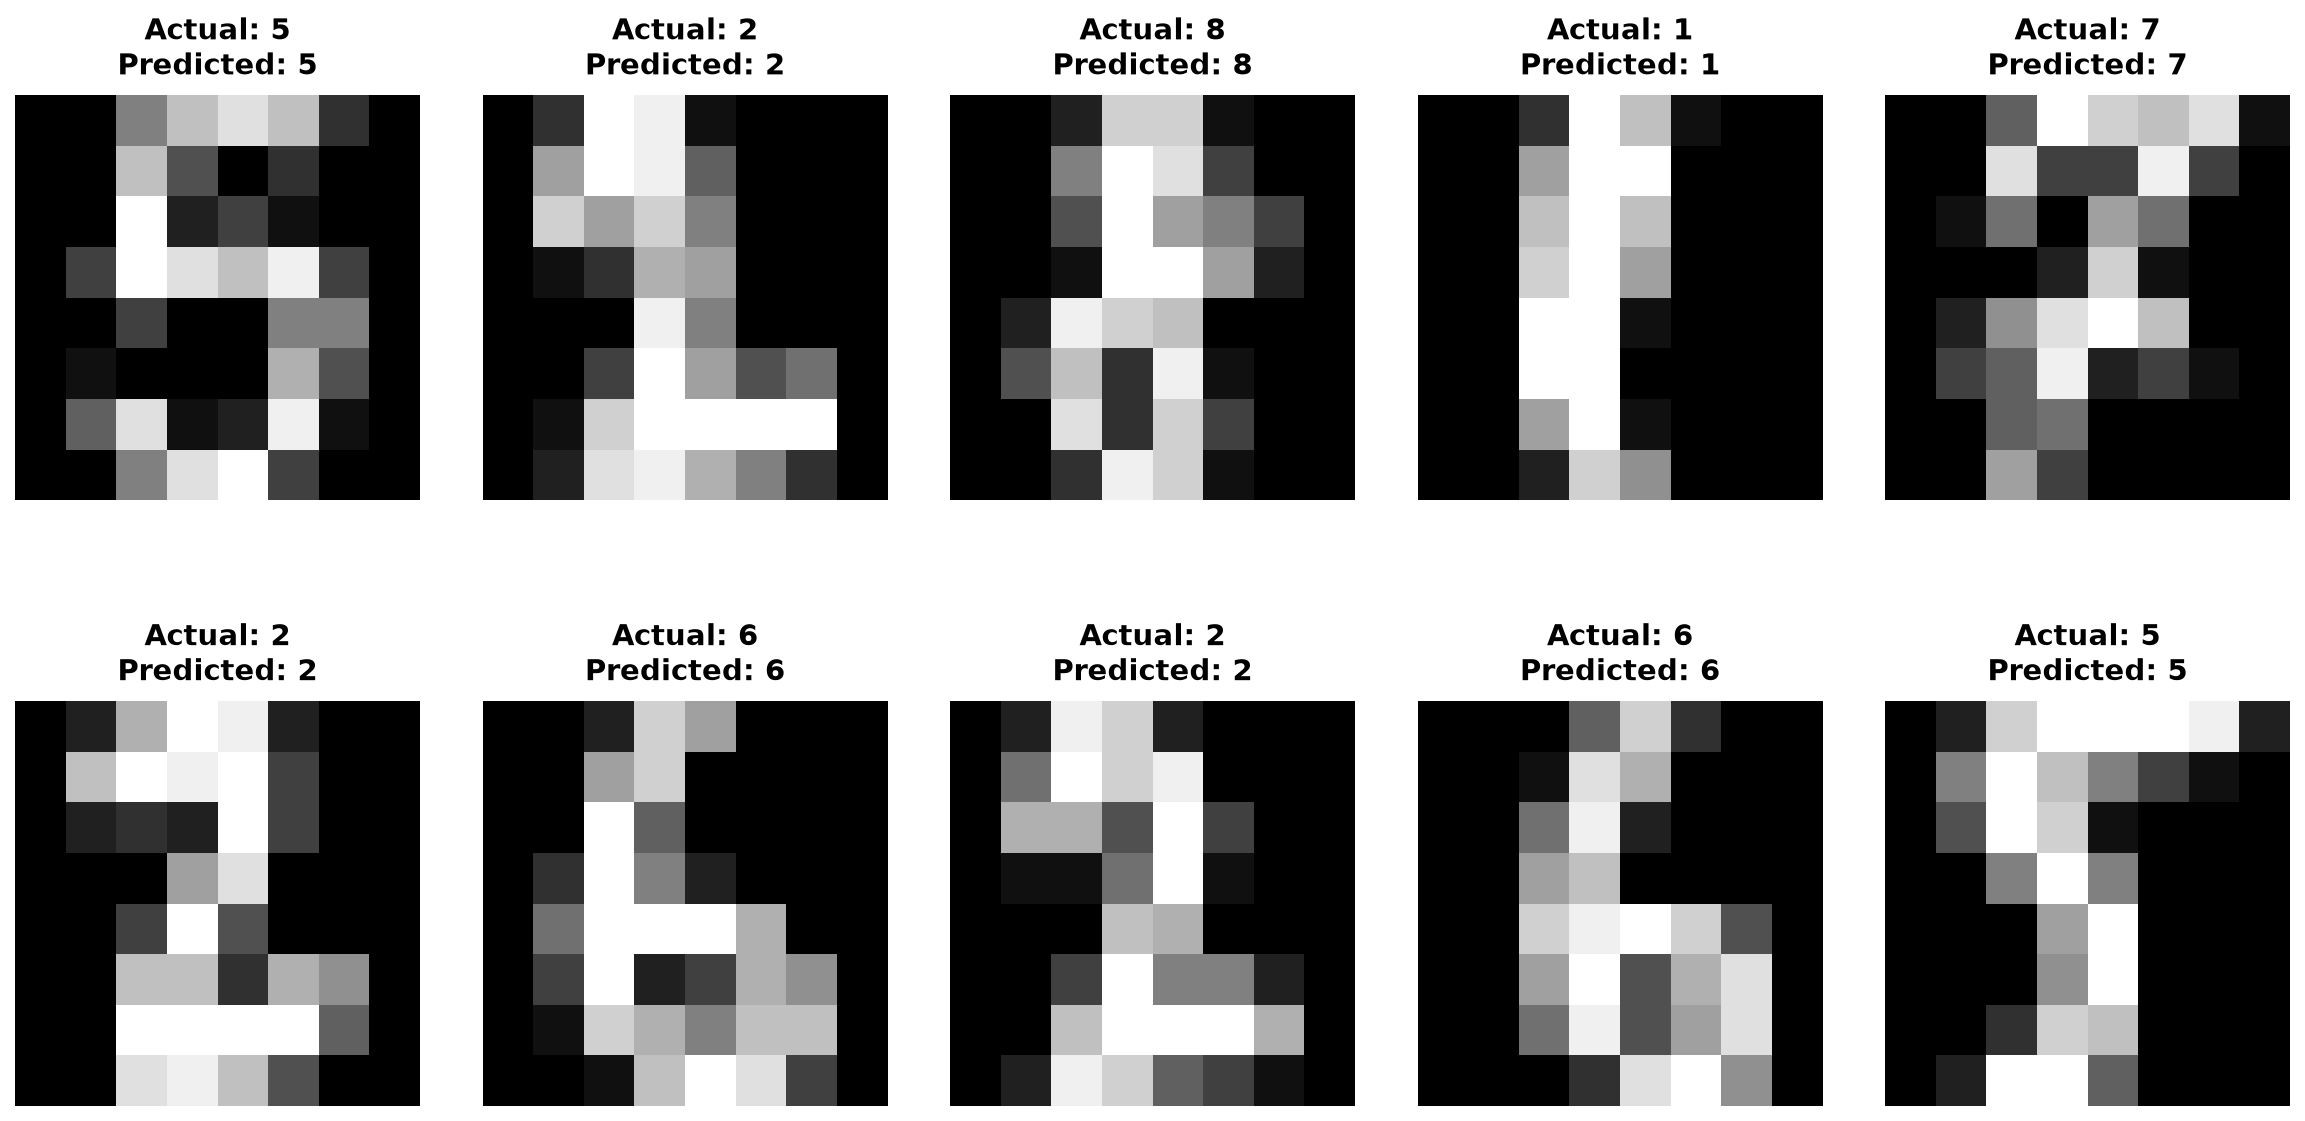

In [32]:

# Display 10 handwritten digits clearly

plt.figure(figsize=(16, 9), dpi=150)

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Display original handwritten image
    plt.imshow(
        digits.images[test_idx[i]],
        cmap="gray",
        interpolation="nearest",
        vmin=0,
        vmax=16
    )

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}",
        fontsize=14,
        fontweight="bold",
        pad=10
    )

    plt.axis("off")

plt.tight_layout(pad=3)
plt.show()


 Step 14: Test a single handwritten digit

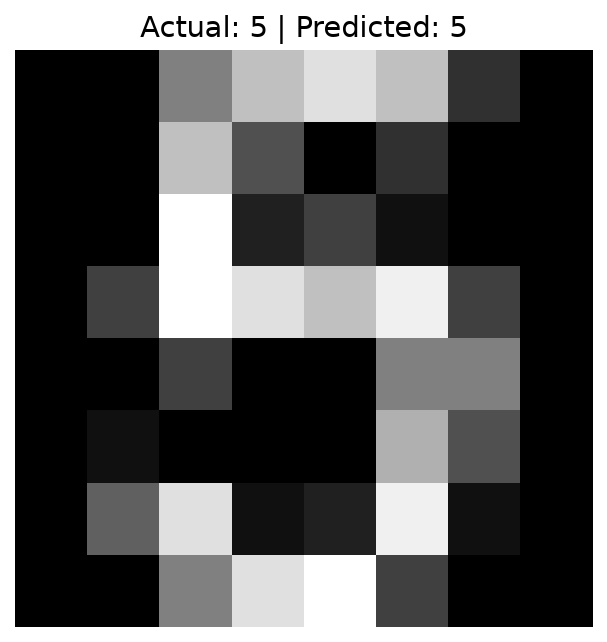

Predicted Digit: 5


In [35]:

# Test a single handwritten digit

i = 0

prediction = svm_model.predict(X_test[i].reshape(1, -1))

plt.figure(figsize=(5, 5), dpi=150)
plt.imshow(digits.images[test_idx[i]], cmap="gray", interpolation="nearest")
plt.title(f"Actual: {y_test[i]} | Predicted: {prediction[0]}", fontsize=14)
plt.axis("off")
plt.show()

print("Predicted Digit:", prediction[0])
